## How DBSCAN Works?

In [15]:
# ![dbscan.gif](attachment:dbscan.gif)


In [16]:
# ![DBSCAN_search.gif](attachment:DBSCAN_search.gif)


## 1. Import Necessary Libraries

In [46]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans,AgglomerativeClustering
import scipy.cluster.hierarchy as sch

from sklearn.cluster import DBSCAN

import warnings
warnings.filterwarnings("ignore")

## Data Collection - Moons Dataset

In [22]:
X,y = make_moons(100)

In [23]:
y

array([0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1])

In [24]:
data = pd.DataFrame(X)
data

,0,1
0,-0.926917,0.375267
1,-0.623490,0.781831
2,0.376510,-0.281831
3,0.284528,0.958668
4,0.018441,0.308841
...,...,...
95,0.981559,0.191159
96,1.000000,0.000000
97,-0.462538,0.886599
98,2.000000,0.500000


In [25]:
data.columns = ["f1","f2"]
data

,f1,f2
0,-0.926917,0.375267
1,-0.623490,0.781831
2,0.376510,-0.281831
3,0.284528,0.958668
4,0.018441,0.308841
...,...,...
95,0.981559,0.191159
96,1.000000,0.000000
97,-0.462538,0.886599
98,2.000000,0.500000


In [26]:
data["class"] = y

In [27]:
data.head()

,f1,f2,class
0,-0.926917,0.375267,0
1,-0.623490,0.781831,0
2,0.376510,-0.281831,1
3,0.284528,0.958668,0
4,0.018441,0.308841,1


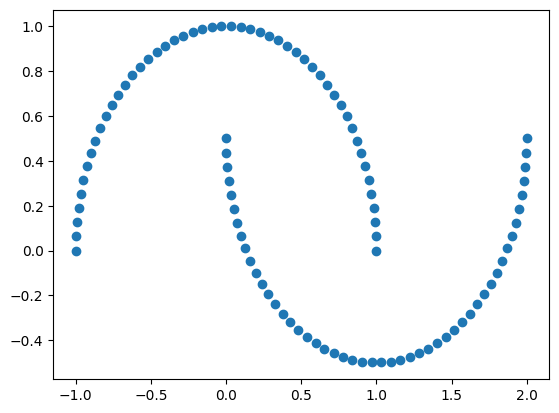

In [28]:
plt.scatter(data["f1"],data["f2"],cmap=plt.cm.Accent)

## The above behaviour is the Original pattern in the Dataset

### Let's apply all 3 Clustering techniques and find out which is BEST

## =================================================================================

## 1. Using Kmeans for moon data

In [29]:
model = KMeans(n_clusters=2, max_iter=600, algorithm= 'lloyd')

In [30]:
model.fit(data.iloc[:,:2])

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,600
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [31]:
claas_pr=model.predict(data.iloc[:,:2])

In [32]:
data["class_pr"]=claas_pr

In [33]:
data.head()

,f1,f2,class,class_pr
0,-0.926917,0.375267,0,0
1,-0.623490,0.781831,0,0
2,0.376510,-0.281831,1,1
3,0.284528,0.958668,0,0
4,0.018441,0.308841,1,0


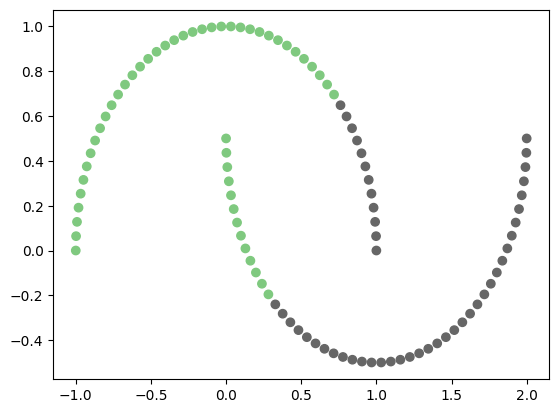

In [34]:
plt.scatter(data["f1"],data["f2"],c=data["class_pr"],cmap=plt.cm.Accent)
plt.show()

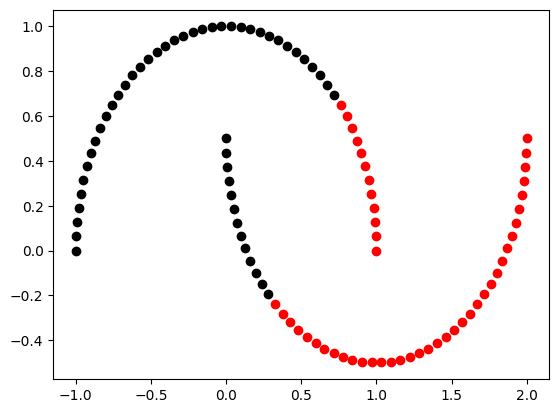

In [35]:
plt.scatter(data[data["class_pr"]==1].iloc[:,0],data[data["class_pr"]==1].iloc[:,1],color = "red")
plt.scatter(data[data["class_pr"]==0].iloc[:,0],data[data["class_pr"]==0].iloc[:,1],color = "black")

### Takeaway: Not accurate

## =======================================================================================

## 2. Using Hierarchical Clustering

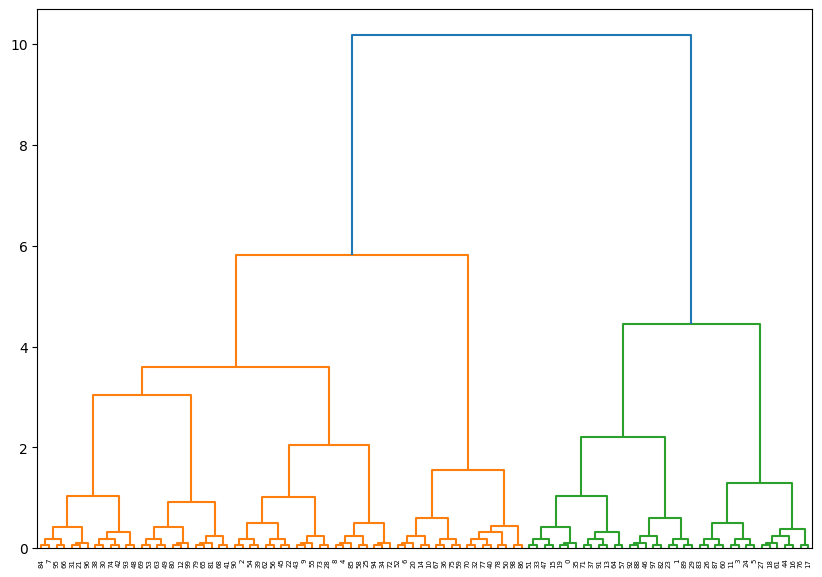

In [38]:
linked = sch.linkage(data.iloc[:,:2], 'ward')

plt.figure(figsize=(10, 7))
sch.dendrogram(linked,
            orientation='top',
            distance_sort='descending',
            show_leaf_counts=True)
plt.show()

In [41]:
cluster = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage="single")
claas_pr = cluster.fit_predict(data.iloc[:,:2])

In [42]:
data["class_pr"] = claas_pr

In [43]:
data.head(20)

,f1,f2,class,class_pr
0,-0.926917,0.375267,0,1
1,-0.623490,0.781831,0,1
2,0.376510,-0.281831,1,0
3,0.284528,0.958668,0,1
4,0.018441,0.308841,1,0
5,0.462538,0.886599,0,1
6,1.838088,-0.045535,1,0
7,0.926917,0.375267,0,1
8,0.008210,0.372123,1,0
9,0.161912,-0.045535,1,0


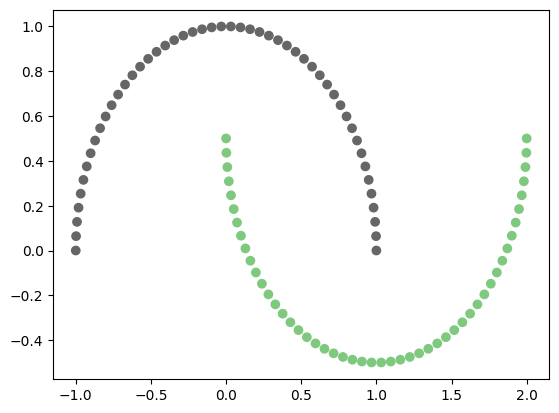

In [44]:
plt.scatter(data["f1"],data["f2"],c=data["class_pr"],cmap=plt.cm.Accent)

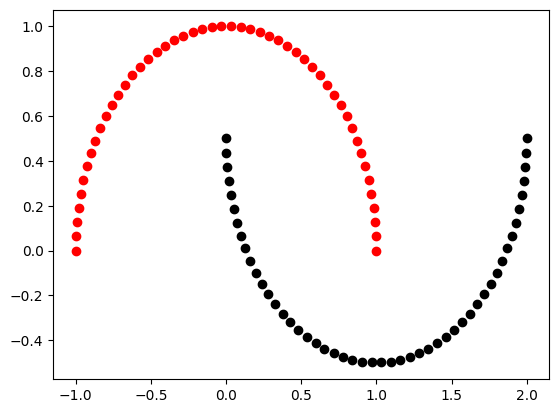

In [45]:
plt.scatter(data[data["class_pr"]==1].iloc[:,0],data[data["class_pr"]==1].iloc[:,1],color = "red")
plt.scatter(data[data["class_pr"]==0].iloc[:,0],data[data["class_pr"]==0].iloc[:,1],color = "black")

### Takeaway: Correct Clustering. Well Done

## =================================================================================

## 3. Applying DBSCAN

In [47]:
mi_samples=2 #n

In [49]:
dbs= DBSCAN(min_samples=2,eps=0.2)
claas_pr = dbs.fit_predict(data.iloc[:,:2])

In [50]:
claas_pr

array([0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1])

In [51]:
data["class_pr"] = claas_pr
data

,f1,f2,class,class_pr
0,-0.926917,0.375267,0,0
1,-0.623490,0.781831,0,0
2,0.376510,-0.281831,1,1
3,0.284528,0.958668,0,0
4,0.018441,0.308841,1,1
...,...,...,...,...
95,0.981559,0.191159,0,0
96,1.000000,0.000000,0,0
97,-0.462538,0.886599,0,0
98,2.000000,0.500000,1,1


Text(0, 0.5, 'f2')

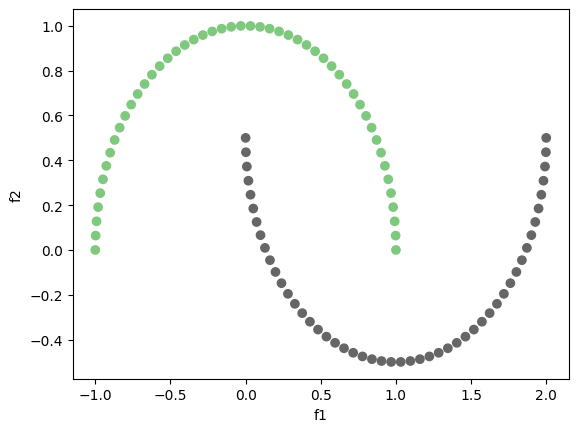

In [52]:
plt.scatter(data["f1"],data["f2"],c=data["class_pr"],cmap=plt.cm.Accent)
plt.xlabel("f1")
plt.ylabel("f2")

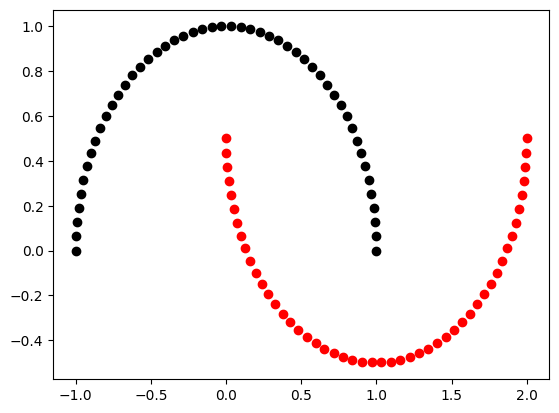

In [53]:
plt.scatter(data[data["class_pr"]==1].iloc[:,0],data[data["class_pr"]==1].iloc[:,1],color="red")
plt.scatter(data[data["class_pr"]==0].iloc[:,0],data[data["class_pr"]==0].iloc[:,1],color="black")

## Takeaway: Correct Clustering. Well Done

## But, Not finding the much difference between Hierarchical VS DBSCAN.

## =====================================================================================

## Logisticdrawback.csv

**This dataset not here**

In [54]:
data = pd.read_csv("logisticdrawback.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'logisticdrawback.csv'

In [70]:
data_1 = data.drop(columns=["class_pr"])

,f1,f2,class
0,-0.926917,0.375267,0
1,-0.623490,0.781831,0
2,0.376510,-0.281831,1
3,0.284528,0.958668,0
4,0.018441,0.308841,1


In [72]:
data_1.head()

,f1,f2,class
0,-0.926917,0.375267,0
1,-0.623490,0.781831,0
2,0.376510,-0.281831,1
3,0.284528,0.958668,0
4,0.018441,0.308841,1


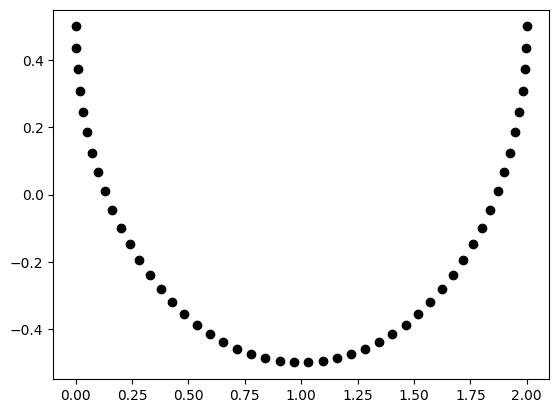

In [74]:
plt.scatter(data[data["class"]==1].iloc[:,0],data[data["class"]==1].iloc[:,1],color="black")
plt.scatter(data[data["class"]==2].iloc[:,0],data[data["class"]==2].iloc[:,1],color="red")
plt.show() 